# Information Theory: From Entropy to Data Compression

## Introduction

In the [previous post](https://blog.vikrampawar.com/how-do-we-quantify-information.html), we developed a way to measure the information gained after observing an event and introduced Shannon entropy, the average information we expect to gain before observing an outcome. We had calculated that for a biased coin with $P(heads)=0.8$, its entropy is $\approx0.722$ bits per toss. Now, suppose we toss the coin 10,000 times, recording heads as 1 and tails as 0 and want to store the resultng sequences efficiently. There are $2^{10000}$ possible sequences of outcomes, so assigning each sequence a unique, fixed-length binary representation requires 10000 bits. 

Can we do better?

In [23]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

jax.config.update('jax_enable_x64', True)

plt.style.use('../mplstyle/blog.mplstyle')
plt.rcParams.update({
    'figure.figsize': (8, 4),
    'axes.grid': True,
    'grid.alpha': 0.18,
    'font.size': 11,
})

random_key = jax.random.PRNGKey(2026)

def information_content(probabilities):
    return -jnp.log2(probabilities)

heads_probability = 0.8
coin_probabilities = jnp.array([1 - heads_probability, heads_probability])

Recall that the information content of the sequence is the sum of the information gained from its individual outcomes:

$$
P(x_1,\ldots,x_N)=\prod_{i=1}^{N}P(x_i),
\qquad
I(x_1,\ldots,x_N)=\sum_{i=1}^{N}I(x_i).
$$

However, not every three-toss sequence provides the same amount of information. Let's compare all eight possible sequences.

In [3]:
from itertools import product

sequences = jnp.array(list(product([0, 1], repeat=3)))
sequence_labels = [''.join(map(str, sequence)) for sequence in sequences]

sequence_probabilities = jnp.prod(coin_probabilities[sequences], axis=1)
sequence_information = information_content(sequence_probabilities)

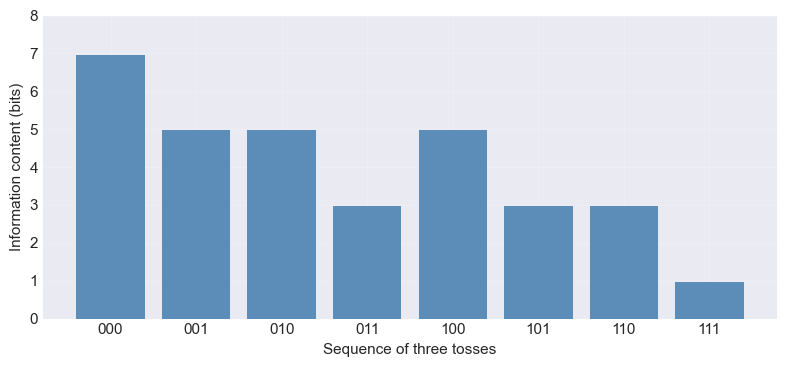

In [4]:
figure, axis = plt.subplots(figsize=(8, 3.8))

axis.bar(sequence_labels, sequence_information, color='#5B8DB8')
axis.set(
    xlabel='Sequence of three tosses',
    ylabel='Information content (bits)',
    ylim=(0, 8),
)

plt.tight_layout()
plt.show()

All eight sequences contain three binary digits, but their information content varies considerably. The sequence `111` is relatively unsurprising because heads are common, whereas `000` is much less likely and therefore carries much more information.

Notice that `011`, `101`, and `110` have the same information content. Each contains two heads and one tail, so their probabilities are equal even though the outcomes occur in a different order.

This doesn't mean that the sequence `000` takes nearly seven bits to write down. Any three-digit binary sequence can be written using three bits. Information content measures how surprising a particular sequence is under our biased coin model; the number of bits used to *encode* it is a separate question that we'll investigate later.

So far, we've calculated the information content of short sequences. But our original question concerns thousands of tosses. What can we say about the information content of a *long* sequence before we know its exact outcomes?

## Information Content of Longer Sequences

We've seen that two sequences of the same length can have very different information content. For our biased coin, a sequence containing more tails is less likely and therefore carries more information than one containing mostly heads.

But what happens as we increase the length of the sequence?

Since the information content of independent observations is additive, we can calculate the total information in a sequence of $N$ tosses by adding the information contributed by each head and tail.

If a sequence contains $k$ heads and $N-k$ tails, its information content is

$$I(\mathbf{x})=-k\log_2 p-(N-k)\log_2(1-p),$$

where $p$ is the probability of heads.

As we increase the number of tosses, the total information will generally increase as well. To compare sequences of different lengths, it makes more sense to calculate the information content *per toss*:

$$\frac{I(\mathbf{x})}{N}.$$

Let's simulate 10,000 independent sequences for each of four different lengths: 10, 100, 1,000, and 10,000 tosses.

For each sequence, we'll calculate its total information content and divide by the number of tosses.

In [5]:
sequence_lengths = [10, 100, 1_000, 10_000]
number_of_experiments = 10_000

coin_information = information_content(coin_probabilities)
information_by_length = {}

for sequence_length in sequence_lengths:
    random_key, sample_key = jax.random.split(random_key)
    head_counts = jax.random.binomial(
        sample_key,
        n=sequence_length,
        p=heads_probability,
        shape=(number_of_experiments,),
    )

    tail_counts = sequence_length - head_counts

    total_information = (
        head_counts * coin_information[1]
        + tail_counts * coin_information[0]
    )
    information_by_length[sequence_length] = (
        total_information / sequence_length
    )

    values = information_by_length[sequence_length]
    print(
        f"N = {sequence_length:>6,}: "
        f"mean = {values.mean():.4f}, "
        f"std = {values.std():.4f}"
    )

N =     10: mean = 0.7243, std = 0.2548
N =    100: mean = 0.7226, std = 0.0803
N =  1,000: mean = 0.7225, std = 0.0255
N = 10,000: mean = 0.7220, std = 0.0080


We don't need to generate and store every individual binary sequence here. Since the tosses are independent and have the same bias, information content depends only on the number of heads and tails. Drawing the head count from a binomial distribution therefore produces the same distribution of information content more efficiently.

Let's plot the information content per toss for each sequence length. The dashed line shows the true entropy of the coin, which we calculated in the previous article.

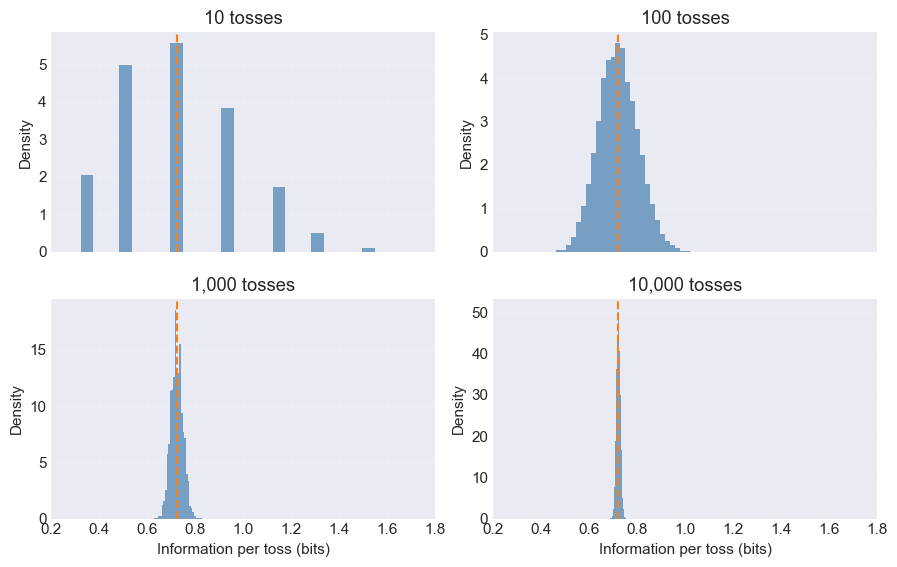

In [6]:
true_entropy = jnp.sum(coin_probabilities * coin_information)

figure, axes = plt.subplots(
    2, 2, figsize=(9, 5.8), sharex=True
)

for axis, (n, values) in zip(
    axes.flat, information_by_length.items()
):
    axis.hist(
        values,
        bins=30,
        density=True,
        color='#5B8DB8',
        alpha=0.8,
    )

    axis.axvline(
        true_entropy,
        linestyle='--',
        color='C1',
    )

    axis.set(
        title=f'{n:,} tosses',
        ylabel='Density',
        xlim=(0.2, 1.8),
    )

for axis in axes[-1]:
    axis.set_xlabel('Information per toss (bits)')

plt.tight_layout()
plt.show()

The difference between short and long sequences is striking.

For sequences of just ten tosses, the information content per toss varies considerably. Some sequences contain an unusually large number of tails and therefore carry much more information than others.

As we increase the sequence length, however, the distribution becomes increasingly concentrated around 0.722 bits per toss.

This value should look familiar. It's the Shannon entropy of our biased coin.

Recall that entropy is the *expected information content of a single toss*. If we repeatedly toss the same coin independently, the information content of each toss is another observation drawn from the same distribution.

The Law of Large Numbers tells us that the average of these observations approaches their expected value as the number of tosses increases.

In our case, this means

$$\frac{I(X_1,\ldots,X_N)}{N}\longrightarrow H(X)$$

as $N$ increases.

Although individual tosses can provide very different amounts of information, the average information per toss becomes increasingly predictable over a long sequence.

For our biased coin, a sufficiently long sequence will therefore typically have an information content close to

$$I(X_1,\ldots,X_N)\approx 0.722N\text{ bits}.$$

This is an interesting result. We cannot predict the exact sequence of outcomes, but we can make an increasingly reliable prediction about its total information content.

What does this tell us about the probability of observing a particular sequence? And why should it help us compress data?

## The Asymptotic Equipartition Property

In the previous experiment, we saw that the information content per toss becomes increasingly concentrated around the entropy of the coin as the sequence gets longer.

Recall that the information content of a sequence is defined as

$$I(\mathbf{x})=-\log_2P(\mathbf{x}),$$

where $P(\mathbf{x})$ is the probability of observing that particular sequence.

We also established that, for a sufficiently long sequence of independent tosses, its information content per toss is likely to be close to the entropy:

$$\frac{I(\mathbf{x})}{N}\approx H(X).$$

Substituting our definition of information content,

$$-\frac{1}{N}\log_2P(\mathbf{x})\approx H(X).$$

Rearranging,

$$\log_2P(\mathbf{x})\approx-NH(X).$$

Taking the power of two on both sides gives us

$$\boxed{P(\mathbf{x})\approx 2^{-NH(X)}.}$$

This is a remarkable result. Although we cannot predict the exact sequence of heads and tails, we can predict the approximate probability of the sequence we are likely to observe, at least on a logarithmic scale.

For our biased coin, the entropy is approximately 0.722 bits per toss. A sequence of 1,000 tosses with information content close to the expected value would therefore have a probability on the order of

$$P(\mathbf{x})\approx 2^{-722}.$$

That's an extraordinarily small probability. But remember that we're talking about the probability of one particular ordered sequence of 1,000 tosses, not the probability of observing any sequence at all.

Let's generate such a sequence and compare its actual information content with our prediction.

In [7]:
sequence_length = 1_000

random_key, sample_key = jax.random.split(random_key)
sequence = jax.random.bernoulli(
    sample_key,
    p=heads_probability,
    shape=(sequence_length,),
).astype(jnp.int32)

log_probability = jnp.log2(coin_probabilities[sequence]).sum()

observed_information = -log_probability / sequence_length
expected_information = true_entropy

print(f"Heads observed: {sequence.sum()}")
print(f"Observed information per toss: {observed_information:.4f} bits")
print(f"Expected information per toss: {expected_information:.4f} bits")
print(f"Log₂ sequence probability: {log_probability:.2f}")
print(f"AEP reference (-NH): {-sequence_length * true_entropy:.2f}")

Heads observed: 805
Observed information per toss: 0.7119 bits
Expected information per toss: 0.7219 bits
Log₂ sequence probability: -711.93
AEP reference (-NH): -721.93


The observed information content is close to the expected value of 0.722 bits per toss. Small deviations are natural: even over 1,000 tosses, the observed proportion of heads need not equal 0.8 exactly.

The agreement becomes more reliable as the sequence length increases. This is a consequence of the Law of Large Numbers, applied to the information content of each toss.

The result is known as the *Asymptotic Equipartition Property*, or AEP.

More precisely, for a sequence of independent, identically distributed observations, AEP tells us that

$$-\frac{1}{N}\log_2P(X_1,\ldots,X_N)\longrightarrow H(X)$$

as the sequence length increases, with probability one.

This does not mean that every possible sequence has the same probability. Nor does it mean that the probability of a sequence becomes numerically equal to $2^{-NH(X)}$.

Rather, for any tolerance $\epsilon>0$, the probability of observing a sequence satisfying

$$H(X)-\epsilon\leq-\frac{1}{N}\log_2P(\mathbf{x})\leq H(X)+\epsilon$$

approaches one as $N$ increases.

Equivalently, such sequences have probabilities satisfying

$$2^{-N(H(X)+\epsilon)}\leq P(\mathbf{x})\leq2^{-N(H(X)-\epsilon)}.$$

In other words, most sufficiently long sequences generated by our coin have an information content per toss close to its entropy.

But this raises an interesting question.

If the probability of any particular long sequence is extraordinarily small, how can we be reasonably confident that the sequence we observe will have an information content close to the entropy?

The answer lies in how many different sequences have this property.

## Not All Sequences Are Equally Likely

The Asymptotic Equipartition Property tells us that most sufficiently long sequences generated by our biased coin have an information content per toss close to its entropy. But the probability of any particular long sequence is extraordinarily small. How can both statements be true?

To answer this, we need to distinguish between the probability of an individual sequence and the combined probability of a *collection* of sequences.

Let's toss our coin six times. Since the coin lands on heads 80% of the time, the most likely individual sequence is `111111`. Its probability is

$$P(111111)=0.8^6\approx0.2621.$$

Now consider `011111`, which contains five heads and one tail. Its probability is

$$P(011111)=0.2\times0.8^5\approx0.0655.$$

This particular sequence is considerably less likely. But the tail could occur in any of the six positions:

`011111`, `101111`, `110111`, `111011`, `111101`, `111110`.

Each arrangement has the same probability. The probability of observing *any sequence containing exactly five heads* is therefore

$$6\times0.8^5\times0.2\approx0.3932.$$

That's about 39.3%, compared with 26.2% for six heads. The most likely individual sequence is not part of the most likely *group* of sequences.

### Counting the possible arrangements

Suppose we toss a coin $N$ times and observe $k$ heads. Every particular ordered sequence with that many heads has probability

$$P(\mathbf{x})=p^k(1-p)^{N-k},$$

where $p$ is the probability of heads. To count the arrangements, we choose which $k$ of the $N$ positions contain heads. There are

$$\binom Nk=\frac{N!}{k!(N-k)!}$$

ways to make this choice. Adding up the probabilities of these arrangements gives

$$\boxed{P(K=k)=\binom Nk p^k(1-p)^{N-k}.}$$

Let's calculate both quantities for each possible number of heads in six tosses.

In [8]:
from math import comb

number_of_tosses = 6
head_counts = jnp.arange(number_of_tosses + 1)

arrangement_counts = jnp.array([
    comb(number_of_tosses, k) for k in range(number_of_tosses + 1)
])

single_sequence_probabilities = (
    heads_probability ** head_counts
    * (1 - heads_probability) ** (number_of_tosses - head_counts)
)

group_probabilities = arrangement_counts * single_sequence_probabilities

print(f"P(six heads): {single_sequence_probabilities[6]:.4f}")
print(f"P(one particular five-head sequence): {single_sequence_probabilities[5]:.4f}")
print(f"P(exactly five heads): {group_probabilities[5]:.4f}")

assert jnp.isclose(group_probabilities.sum(), 1.0)

P(six heads): 0.2621
P(one particular five-head sequence): 0.0655
P(exactly five heads): 0.3932


The first chart shows the probability of **one particular ordered sequence** containing $k$ heads. The second shows the probability of **any sequence** with $k$ heads, accounting for all possible arrangements.

Change the probability of heads or the number of tosses. The highlighted bars mark the highest probabilities in each chart.

In [9]:
import altair as alt
from html import escape
from IPython.display import display

blue = '#5B8DB8'
orange = '#DD8452'
font = 'Arial'

# Precompute the number of arrangements for all supported sequence lengths.
# JAX handles numerical work; Altair receives only JSON-compatible values.
chart_data = alt.Data(values=[
    {'n': n, 'k': k, 'arrangements': comb(n, k)}
    for n in range(2, 31)
    for k in range(n + 1)
])

heads_slider = alt.param(
    name='heads_p', value=heads_probability,
    bind=alt.binding_range(
        min=0.05, max=0.95, step=0.05,
        name='Probability of heads: ',
    ),
)
length_slider = alt.param(
    name='n_tosses', value=number_of_tosses,
    bind=alt.binding_range(
        min=2, max=30, step=1,
        name='Number of tosses: ',
    ),
)

base = (
    alt.Chart(chart_data)
    .transform_filter('datum.n == n_tosses')
    .transform_calculate(
        individual='pow(heads_p, datum.k) * pow(1-heads_p, datum.n-datum.k)',
        grouped='datum.arrangements * datum.individual',
    )
)


def probability_panel(field, title, peak_test):
    return (
        base.mark_bar()
        .encode(
            x=alt.X('k:O', title='Number of heads (k)',
                    sort='ascending', axis=alt.Axis(labelAngle=0)),
            y=alt.Y(f'{field}:Q', title='Probability',
                    scale=alt.Scale(zero=True)),
            color=alt.condition(
                peak_test, alt.value(orange), alt.value(blue),
            ),
            tooltip=[
                alt.Tooltip('k:Q', title='Heads'),
                alt.Tooltip('arrangements:Q', title='Arrangements', format=','),
                alt.Tooltip(f'{field}:Q', title='Probability', format='.5f'),
            ],
        )
        .properties(width='container', height=220, title=title)
    )

peak_individual = (
    'abs(heads_p-0.5) < 1e-9 || '
    'datum.k == (heads_p > 0.5 ? datum.n : 0)'
)
mode = 'floor((datum.n + 1)*heads_p)'
peak_group = (
    f'datum.k == {mode} || '
    f'(abs((datum.n+1)*heads_p - {mode}) < 1e-9 && datum.k == {mode}-1)'
)

probability_chart = (
    alt.vconcat(
        probability_panel('individual', 'Probability of one particular sequence', peak_individual),
        probability_panel('grouped', 'Probability of any sequence with k heads', peak_group),
        spacing=28,
    )
    .add_params(heads_slider, length_slider)
    .resolve_scale(y='independent')
    .configure_view(fill='#EAEAF2', stroke=None)
    .configure_axis(
        labelFont=font, titleFont=font,
        labelFontSize=13, titleFontSize=14,
        titleFontWeight='normal',
        labelColor='#415061', titleColor='#303846',
        gridColor='#FFFFFF', gridWidth=1,
        domain=False, tickSize=0,
        labelPadding=7, titlePadding=11,
    )
    .configure_title(
        font=font, fontSize=16, fontWeight='normal',
        anchor='start', color='#303846', offset=10,
    )
    .properties(background='#FFFFFF')
)

# The iframe is just tall enough for both fixed-height panels and slider controls.
# Its width adapts to the notebook, with no extra blank area underneath.
chart_css = "<style>\n:root { color-scheme: light; }\nhtml, body { margin: 0; padding: 0; width: 100%; overflow-x: hidden; background: #FFFFFF; }\nbody { box-sizing: border-box; padding: 12px 8px; font: 14px/1.4 Arial, Helvetica, sans-serif; color: #303846; }\n#vis { width: 100%; min-width: 0; }\n.vega-embed { display: flex !important; flex-direction: column !important; align-items: stretch !important; width: 100% !important; padding-right: 0 !important; box-sizing: border-box !important; }\n.vega-bindings { order: -1 !important; display: flex !important; align-items: center !important; justify-content: flex-start !important; flex-wrap: wrap !important; gap: 10px 26px !important; width: 100% !important; margin: 0 0 22px 0 !important; padding: 4px 2px 12px 8px !important; box-sizing: border-box !important; border-bottom: 1px solid #e1e4e8; }\n.vega-bindings .vega-bind { display: flex !important; align-items: center !important; gap: 9px !important; margin: 0 !important; font: 14px Arial, Helvetica, sans-serif !important; }\n.vega-bindings .vega-bind-name { font: 14px Arial, Helvetica, sans-serif !important; color: #303846 !important; }\n.vega-bindings input[type='range'] { width: 150px; accent-color: #5B8DB8; cursor: pointer; }\n.vega-bindings select, .vega-bindings input { font-family: Arial, Helvetica, sans-serif !important; font-size: 14px !important; }\n.vega-embed .vega-actions { display: none !important; }\n.vega-embed svg { max-width: 100%; height: auto; }\n@media (max-width: 600px) { .vega-bindings { gap: 12px !important; } .vega-bindings .vega-bind { flex-wrap: wrap !important; } }\n</style>"
chart_html = probability_chart.to_html(embed_options={'actions': False, 'renderer': 'svg'})
chart_html = chart_html.replace('</head>', chart_css + '</head>')
iframe_html = (
    '<iframe title="Interactive binomial probabilities" '
    'sandbox="allow-scripts" '
    'style="display:block;width:100%;height:670px;max-width:100%;border:0" '
    f'srcdoc="{escape(chart_html, quote=True)}"></iframe>'
)
# A raw HTML mime-bundle avoids IPython's iframe HTML() warning.
display({'text/html': iframe_html}, raw=True)


<iframe title="Interactive binomial probabilities" sandbox="allow-scripts" style="display:block;width:100%;height:670px;max-width:100%;border:0" srcdoc="<!DOCTYPE html>
<html>
<head>
 <meta charset="UTF-8">
 <style>
 #vis.vega-embed {
 width: 100%;
 display: flex;
 }

 #vis.vega-embed details,
 #vis.vega-embed details summary {
 position: relative;
 }
 </style>
 <script type="text/javascript" src="https://cdn.jsdelivr.net/npm/vega@6"></script>
 <script type="text/javascript" src="https://cdn.jsdelivr.net/npm/vega-lite@6.4.1"></script>
 <script type="text/javascript" src="https://cdn.jsdelivr.net/npm/vega-embed@7"></script>
<style>
:root { color-scheme: light; }
html, body { margin: 0; padding: 0; width: 100%; overflow-x: hidden; background: #FFFFFF; }
body { box-sizing: border-box; padding: 12px 8px; font: 14px/1.4 Arial, Helvetica, sans-serif; color: #303846; }
#vis { width: 100%; min-width: 0; }
.vega-embed { display: flex !important; flex-direction: column !important; align-items: stretch !important; width: 100% !important; padding-right: 0 !important; box-sizing: border-box !important; }
.vega-bindings { order: -1 !important; display: flex !important; align-items: center !important; justify-content: flex-start !important; flex-wrap: wrap !important; gap: 10px 26px !important; width: 100% !important; margin: 0 0 22px 0 !important; padding: 4px 2px 12px 8px !important; box-sizing: border-box !important; border-bottom: 1px solid #e1e4e8; }
.vega-bindings .vega-bind { display: flex !important; align-items: center !important; gap: 9px !important; margin: 0 !important; font: 14px Arial, Helvetica, sans-serif !important; }
.vega-bindings .vega-bind-name { font: 14px Arial, Helvetica, sans-serif !important; color: #303846 !important; }
.vega-bindings input[type='range'] { width: 150px; accent-color: #5B8DB8; cursor: pointer; }
.vega-bindings select, .vega-bindings input { font-family: Arial, Helvetica, sans-serif !important; font-size: 14px !important; }
.vega-embed .vega-actions { display: none !important; }
.vega-embed svg { max-width: 100%; height: auto; }
@media (max-width: 600px) { .vega-bindings { gap: 12px !important; } .vega-bindings .vega-bind { flex-wrap: wrap !important; } }
</style></head>
<body>
 <div id="vis"></div>
 <script>
 (function(vegaEmbed) {
 var spec = {"config": {"view": {"continuousWidth": 300, "continuousHeight": 300, "fill": "#EAEAF2", "stroke": null}, "axis": {"domain": false, "gridColor": "#FFFFFF", "gridWidth": 1, "labelColor": "#415061", "labelFont": "Arial", "labelFontSize": 13, "labelPadding": 7, "tickSize": 0, "titleColor": "#303846", "titleFont": "Arial", "titleFontSize": 14, "titleFontWeight": "normal", "titlePadding": 11}, "title": {"anchor": "start", "color": "#303846", "font": "Arial", "fontSize": 16, "fontWeight": "normal", "offset": 10}}, "vconcat": [{"mark": {"type": "bar"}, "encoding": {"color": {"condition": {"test": "abs(heads_p-0.5) < 1e-9 || datum.k == (heads_p > 0.5 ? datum.n : 0)", "value": "#DD8452"}, "value": "#5B8DB8"}, "tooltip": [{"field": "k", "title": "Heads", "type": "quantitative"}, {"field": "arrangements", "format": ",", "title": "Arrangements", "type": "quantitative"}, {"field": "individual", "format": ".5f", "title": "Probability", "type": "quantitative"}], "x": {"axis": {"labelAngle": 0}, "field": "k", "sort": "ascending", "title": "Number of heads (k)", "type": "ordinal"}, "y": {"field": "individual", "scale": {"zero": true}, "title": "Probability", "type": "quantitative"}}, "height": 220, "title": "Probability of one particular sequence", "transform": [{"filter": "datum.n == n_tosses"}, {"calculate": "pow(heads_p, datum.k) * pow(1-heads_p, datum.n-datum.k)", "as": "individual"}, {"calculate": "datum.arrangements * datum.individual", "as": "grouped"}], "width": "container"}, {"mark": {"type": "bar"}, "encoding": {"color": {"condition": {"test": "datum.k == floor((datum.n + 1)*heads_p) || (abs((datum.n+1)*heads_p - floor((datum.n + 1)*heads_p)) < 1e-9 && datum.k == flo

The two distributions behave differently. In the first chart, a sequence becomes more probable as we replace tails with heads. When $p=0.8$, the most probable individual sequence contains only heads.

But the second chart also accounts for the number of possible arrangements. There is only one arrangement containing six heads, six containing five heads, and fifteen containing four heads. The six five-head sequences together are more probable than the one all-head sequence.

Try increasing the number of tosses in the interactive chart. The all-head sequence remains the most likely individual sequence, but the largest groups have head counts near $Np$. As $N$ grows, the probability of even the most likely individual sequence becomes very small, while large groups of more representative sequences collectively dominate.

This helps explain our earlier AEP result. A typical long sequence doesn't need to be individually likely. It can belong to a very large collection that together accounts for almost all the probability.

But how large is that collection? Does it contain most of the $2^N$ possible binary strings, or only a small fraction of them?

That leads us to the idea of a *typical set*.

## Typical Sets: Where Most of the Probability Is Concentrated

In the previous section, we saw that the most probable individual sequence need not be representative of what we're likely to observe. We also learned from the Asymptotic Equipartition Property (AEP) that long sequences tend to have an information content per toss close to the entropy.

How many sequences have this property?

### Defining a typical sequence

For a sequence $\mathbf{x}$ of $N$ tosses, its information content per toss is

$$\frac{I(\mathbf{x})}{N}=-\frac{1}{N}\log_2P(\mathbf{x}).$$

Let's choose a tolerance $\epsilon>0$ and call a sequence *typical* when its information content per toss differs from entropy by at most $\epsilon$ bits:

$$\left|\frac{I(\mathbf{x})}{N}-H(X)\right|\leq\epsilon.$$

The set of all such sequences is called the *typical set*, denoted by

$$A_\epsilon^{(N)}=\left\{\mathbf{x}:\left|\frac{I(\mathbf{x})}{N}-H(X)\right|\leq\epsilon\right\}.$$

For a coin that lands on heads with probability $p$, a sequence with $k$ heads and $N-k$ tails has information content per toss

$$\frac{I(\mathbf{x})}{N}=-\frac{k}{N}\log_2p-\left(1-\frac{k}{N}\right)\log_2(1-p).$$

With $p=0.8$, this becomes

$$\frac{I(\mathbf{x})}{N}\approx2.3219-2\frac{k}{N}.$$

The entropy is approximately $0.7219$ bits per toss. If we set $\epsilon=0.1$, the allowed information content lies between $0.6219$ and $0.8219$ bits per toss. Substituting into the expression above gives

$$0.75\leq\frac{k}{N}\leq0.85.$$

So a sequence is typical if between 75% and 85% of its tosses are heads. For $N=100$, that means between 75 and 85 heads, inclusive.

Let's see which head counts belong to the typical set and how much probability they account for.

In [10]:
# Interactive typical-set explorer (Altair)
from html import escape
from IPython.display import display

# JAX computes the experimental results; this small JSON dataset
# supplies exact arrangement counts to the browser-side chart.
typical_chart_data = alt.Data(values=[
    {'n': n, 'k': k, 'arrangements': comb(n, k)}
    for n in [20, 50, 100, 200]
    for k in range(n + 1)
])

p_control = alt.param(
    name='typical_p', value=heads_probability,
    bind=alt.binding_range(
        min=0.55, max=0.95, step=0.05,
        name='Probability of heads: ',
    ),
)
n_control = alt.param(
    name='typical_n', value=100,
    bind=alt.binding_select(
        options=[20, 50, 100, 200],
        name='Sequence length: ',
    ),
)
epsilon_control = alt.param(
    name='typical_epsilon', value=0.1,
    bind=alt.binding_range(
        min=0.02, max=0.2, step=0.02,
        name='Tolerance (ε): ',
    ),
)

typical_base = (
    alt.Chart(typical_chart_data)
    .transform_filter('datum.n == typical_n')
    .transform_calculate(
        entropy='-(typical_p*log(typical_p) + (1-typical_p)*log(1-typical_p))/log(2)',
        information='-(datum.k*log(typical_p) + (datum.n-datum.k)*log(1-typical_p))/(datum.n*log(2))',
        probability='datum.arrangements * pow(typical_p, datum.k) * pow(1-typical_p, datum.n-datum.k)',
        fraction='datum.arrangements / pow(2, datum.n)',
        x_start='datum.k - 0.46',
        x_end='datum.k + 0.46',
        expected_heads='datum.n * typical_p',
    )
    .transform_calculate(
        typical='abs(datum.information - datum.entropy) <= typical_epsilon + 1e-10',
    )
)

# Display only head counts within four standard deviations of Np.
# This affects the viewport, not the typical-set statistics below.
zoom_filter = (
    'datum.k >= max(0, floor(datum.expected_heads - '
    '4*sqrt(datum.n*typical_p*(1-typical_p)))) && '
    'datum.k <= min(datum.n, ceil(datum.expected_heads + '
    '4*sqrt(datum.n*typical_p*(1-typical_p))))'
)
visible_counts = (
    typical_base
    .transform_filter(zoom_filter)
    .transform_calculate(
        category="datum.typical ? 'Typical' : 'Atypical'",
        baseline='0',
    )
)

# A rectangle with explicit left/right and bottom/top edges guarantees
# full-height vertical columns, regardless of Vega-Lite bar orientation.
bars = visible_counts.mark_rect(stroke='#FFFFFF', strokeWidth=0.6).encode(
    x=alt.X(
        'x_start:Q', title='Number of heads (k)',
        axis=alt.Axis(tickMinStep=1),
        scale=alt.Scale(zero=False, nice=False),
    ),
    x2='x_end:Q',
    y=alt.Y(
        'probability:Q', title='Probability',
        scale=alt.Scale(zero=True, domainMin=0, nice=False),
    ),
    y2='baseline:Q',
    color=alt.Color(
        'category:N',
        scale=alt.Scale(
            domain=['Typical', 'Atypical'],
            range=['#5B8DB8', '#D7DCE3'],
        ),
        legend=alt.Legend(
            title=None, orient='top', direction='horizontal',
            labelFont='Arial', labelFontSize=13,
            labelColor='#303846', symbolType='square',
        ),
    ),
    tooltip=[
        alt.Tooltip('k:Q', title='Heads'),
        alt.Tooltip('information:Q', title='Information per toss', format='.3f'),
        alt.Tooltip('probability:Q', title='Group probability', format='.5f'),
        alt.Tooltip('typical:N', title='Typical'),
    ],
)
reference = (
    typical_base
    .transform_aggregate(expected_heads='max(expected_heads)')
    .mark_rule(color='#DD8452', strokeDash=[6, 4], strokeWidth=2)
    .encode(x=alt.X('expected_heads:Q'))
)

probability_panel = alt.layer(bars, reference).properties(
    width='container', height=270,
    title='Which head counts belong to the typical set?',
)

summary_data = (
    typical_base
    .transform_calculate(
        included_mass='datum.typical ? datum.probability : 0',
        included_fraction='datum.typical ? datum.fraction : 0',
    )
    .transform_aggregate(
        mass='sum(included_mass)',
        fraction='sum(included_fraction)',
    )
    .transform_calculate(
        mass_label="'Typical-set probability mass: ' + format(datum.mass, '.4%')",
        fraction_label="'Fraction of all sequences: ' + format(datum.fraction, '.2e')",
    )
)

mass_label = (
    summary_data.mark_text(align='left', baseline='middle',
                           font='Arial', fontSize=14, color='#303846')
    .encode(x=alt.value(12), y=alt.value(12), text='mass_label:N')
    .properties(width='container', height=23)
)
fraction_label = (
    summary_data.mark_text(align='left', baseline='middle',
                           font='Arial', fontSize=14, color='#303846')
    .encode(x=alt.value(12), y=alt.value(12), text='fraction_label:N')
    .properties(width='container', height=23)
)

typical_chart = (
    alt.vconcat(probability_panel, mass_label, fraction_label, spacing=9)
    .add_params(p_control, n_control, epsilon_control)
    .configure_view(fill='#EAEAF2', stroke=None)
    .configure_axis(
        labelFont='Arial', titleFont='Arial',
        labelFontSize=13, titleFontSize=14,
        titleFontWeight='normal',
        labelColor='#415061', titleColor='#303846',
        gridColor='#FFFFFF', gridWidth=1,
        domain=False, tickSize=0,
        labelPadding=7, titlePadding=11,
    )
    .configure_title(
        font='Arial', fontSize=16, fontWeight='normal',
        anchor='start', color='#303846', offset=10,
    )
    .properties(background='#FFFFFF')
)

# Isolate the chart in a bounded frame, matching the earlier Altair plot.
typical_html = typical_chart.to_html(embed_options={'actions': False, 'renderer': 'svg'})
typical_html = typical_html.replace('</head>', chart_css + '</head>')
typical_iframe = (
    '<iframe title="Interactive typical-set explorer" sandbox="allow-scripts" '
    'style="display:block;width:100%;height:570px;max-width:100%;border:0" '
    f'srcdoc="{escape(typical_html, quote=True)}"></iframe>'
)
display({'text/html': typical_iframe}, raw=True)

<iframe title="Interactive typical-set explorer" sandbox="allow-scripts" style="display:block;width:100%;height:570px;max-width:100%;border:0" srcdoc="<!DOCTYPE html>
<html>
<head>
 <meta charset="UTF-8">
 <style>
 #vis.vega-embed {
 width: 100%;
 display: flex;
 }

 #vis.vega-embed details,
 #vis.vega-embed details summary {
 position: relative;
 }
 </style>
 <script type="text/javascript" src="https://cdn.jsdelivr.net/npm/vega@6"></script>
 <script type="text/javascript" src="https://cdn.jsdelivr.net/npm/vega-lite@6.4.1"></script>
 <script type="text/javascript" src="https://cdn.jsdelivr.net/npm/vega-embed@7"></script>
<style>
:root { color-scheme: light; }
html, body { margin: 0; padding: 0; width: 100%; overflow-x: hidden; background: #FFFFFF; }
body { box-sizing: border-box; padding: 12px 8px; font: 14px/1.4 Arial, Helvetica, sans-serif; color: #303846; }
#vis { width: 100%; min-width: 0; }
.vega-embed { display: flex !important; flex-direction: column !important; align-items: stretch !important; width: 100% !important; padding-right: 0 !important; box-sizing: border-box !important; }
.vega-bindings { order: -1 !important; display: flex !important; align-items: center !important; justify-content: flex-start !important; flex-wrap: wrap !important; gap: 10px 26px !important; width: 100% !important; margin: 0 0 22px 0 !important; padding: 4px 2px 12px 8px !important; box-sizing: border-box !important; border-bottom: 1px solid #e1e4e8; }
.vega-bindings .vega-bind { display: flex !important; align-items: center !important; gap: 9px !important; margin: 0 !important; font: 14px Arial, Helvetica, sans-serif !important; }
.vega-bindings .vega-bind-name { font: 14px Arial, Helvetica, sans-serif !important; color: #303846 !important; }
.vega-bindings input[type='range'] { width: 150px; accent-color: #5B8DB8; cursor: pointer; }
.vega-bindings select, .vega-bindings input { font-family: Arial, Helvetica, sans-serif !important; font-size: 14px !important; }
.vega-embed .vega-actions { display: none !important; }
.vega-embed svg { max-width: 100%; height: auto; }
@media (max-width: 600px) { .vega-bindings { gap: 12px !important; } .vega-bindings .vega-bind { flex-wrap: wrap !important; } }
</style></head>
<body>
 <div id="vis"></div>
 <script>
 (function(vegaEmbed) {
 var spec = {"config": {"view": {"continuousWidth": 300, "continuousHeight": 300, "fill": "#EAEAF2", "stroke": null}, "axis": {"domain": false, "gridColor": "#FFFFFF", "gridWidth": 1, "labelColor": "#415061", "labelFont": "Arial", "labelFontSize": 13, "labelPadding": 7, "tickSize": 0, "titleColor": "#303846", "titleFont": "Arial", "titleFontSize": 14, "titleFontWeight": "normal", "titlePadding": 11}, "title": {"anchor": "start", "color": "#303846", "font": "Arial", "fontSize": 16, "fontWeight": "normal", "offset": 10}}, "vconcat": [{"layer": [{"mark": {"type": "rect", "stroke": "#FFFFFF", "strokeWidth": 0.6}, "encoding": {"color": {"field": "category", "legend": {"direction": "horizontal", "labelColor": "#303846", "labelFont": "Arial", "labelFontSize": 13, "orient": "top", "symbolType": "square", "title": null}, "scale": {"domain": ["Typical", "Atypical"], "range": ["#5B8DB8", "#D7DCE3"]}, "type": "nominal"}, "tooltip": [{"field": "k", "title": "Heads", "type": "quantitative"}, {"field": "information", "format": ".3f", "title": "Information per toss", "type": "quantitative"}, {"field": "probability", "format": ".5f", "title": "Group probability", "type": "quantitative"}, {"field": "typical", "title": "Typical", "type": "nominal"}], "x": {"axis": {"tickMinStep": 1}, "field": "x_start", "scale": {"nice": false, "zero": false}, "title": "Number of heads (k)", "type": "quantitative"}, "x2": {"field": "x_end"}, "y": {"field": "probability", "scale": {"domainMin": 0, "nice": false, "zero": true}, "title": "Probability", "type": "quantitative"}, "y2": {"field": "baseline"}}, "transform": [{"filter": "datum.n == typical_n"}, {"calculate": "-(typical_p*log(typical_p) + (1-typical_p)

The blue bars identify head counts whose sequences belong to the typical set. Each bar represents the probability of **all** sequences with that head count, not just one sequence. The dashed orange line marks the expected number of heads, $Np$. For readability, the chart shows only head counts within four standard deviations, $4\sqrt{Np(1-p)}$, of that expectation. The statistics beneath the plot still use **all** possible head counts.

Try varying the probability of heads, sequence length, and tolerance. A wider tolerance admits more sequences, but also increases the fraction of all binary strings classified as typical.

### Counting typical sequences

If $T_N$ is the set of head counts satisfying our typicality condition, then every one of the $\binom Nk$ arrangements for each $k\in T_N$ is typical. The total number of typical sequences is therefore

$$|A_\epsilon^{(N)}|=\sum_{k\in T_N}\binom Nk.$$

There are $2^N$ possible binary strings of length $N$, so the fraction of all strings that are typical is

$$f_N=\frac{|A_\epsilon^{(N)}|}{2^N}.$$

But this is different from the probability that our *biased coin* produces a typical sequence. That probability is

$$M_N=\sum_{k\in T_N}\binom Nk p^k(1-p)^{N-k}.$$

The fraction $f_N$ treats all binary strings equally when counting them. The probability mass $M_N$ weights each string according to how likely the biased coin is to produce it.

We can calculate both quantities without enumerating all $2^N$ strings: it is enough to sum over the $N+1$ possible head counts. For long sequences we'll perform those sums in logarithmic space to avoid underflow.

In [11]:
from jax.scipy.special import logsumexp
from jax.scipy.stats import binom


def typical_set_statistics(n, p, epsilon):
    k = jnp.arange(n + 1)

    probabilities = jnp.array([1 - p, p])
    entropy_value = jnp.sum(
        probabilities * information_content(probabilities)
    )

    information_per_toss = -(
        k * jnp.log2(p)
        + (n - k) * jnp.log2(1 - p)
    ) / n

    typical = (
        jnp.abs(information_per_toss - entropy_value)
        <= epsilon + 1e-12
    )

    log_fraction = logsumexp(jnp.where(
        typical, binom.logpmf(k, n, 0.5), -jnp.inf
    ))
    log_mass = logsumexp(jnp.where(
        typical, binom.logpmf(k, n, p), -jnp.inf
    ))

    return log_fraction, jnp.exp(log_mass)

In [12]:
epsilon = 0.1
sequence_lengths = [20, 50, 100, 200, 500, 1_000]

typical_masses = []
log_typical_fractions = []

for n in sequence_lengths:
    log_fraction, mass = typical_set_statistics(
        n, heads_probability, epsilon
    )

    typical_masses.append(mass)
    log_typical_fractions.append(log_fraction)

    print(
        f"N = {n:>5,}: "
        f"mass = {float(mass):.6f}, "
        f"fraction = {float(jnp.exp(log_fraction)):.3e}"
    )

N =    20: mass = 0.598123, fraction = 2.049e-02
N =    50: mass = 0.623533, fraction = 1.528e-04
N =   100: mass = 0.832081, fraction = 2.818e-07
N =   200: mass = 0.937227, fraction = 4.197e-13
N =   500: mass = 0.995658, fraction = 2.418e-30
N = 1,000: mass = 0.999931, fraction = 6.738e-59


/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_61979/1620067285.py:20: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
/var/folders/x4/85_9sn3d1ng9q48ff6t3fw340000gn/T/ipykernel_61979/1620067285.py:20: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  plt.tight_layout()
/Users/vikram/dev/vikrampawar.com/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/vikram/dev/vikrampawar.com/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8320 (\N{SUBSCRIPT ZERO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


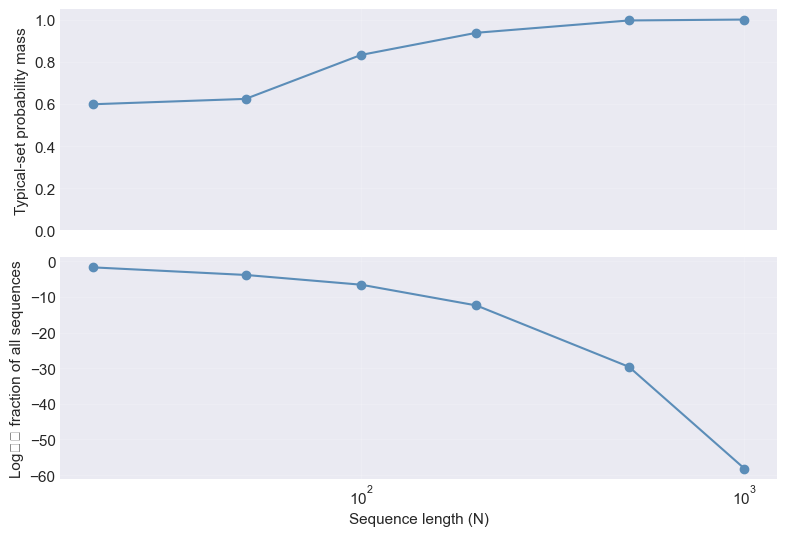

In [13]:
figure, axes = plt.subplots(2, 1, figsize=(8, 5.5), sharex=True)

axes[0].plot(sequence_lengths, typical_masses, marker='o', color='#5B8DB8')
axes[0].set(
    ylabel='Typical-set probability mass',
    ylim=(0, 1.05),
)

axes[1].plot(
    sequence_lengths,
    jnp.array(log_typical_fractions) / jnp.log(10),
    marker='o', color='#5B8DB8',
)
axes[1].set(
    xlabel='Sequence length (N)',
    ylabel='Log₁₀ fraction of all sequences',
    xscale='log',
)

plt.tight_layout()
plt.show()

### Almost all the probability, in a tiny fraction of sequences

For sequences of 100 tosses, the typical set contains only about $2.82\times10^{-7}$ of all possible binary strings, yet it accounts for approximately 83.2% of the probability.

For sequences of 1,000 tosses, the contrast is much sharper: the typical set contains only about

$$6.74\times10^{-59}$$

of all possible binary strings, but the probability that our biased coin produces one of them is approximately $0.999931$.

If we choose a binary string uniformly at random from all $2^{1000}$ possibilities, it is extraordinarily unlikely to fall in this typical set. If we instead generate it by tossing our biased coin, it is almost certain to do so.

The probability mass need not increase at every single sequence length, because the allowed numbers of heads are integers. But the AEP guarantees that, for any fixed positive tolerance, the probability mass of the typical set approaches one as $N$ increases. For our particular coin and tolerance, the fraction of all binary strings belonging to that set simultaneously becomes vanishingly small.

### Why does this matter for compression?

To distinguish between all $2^N$ possible sequences with fixed-length indices, we need $N$ bits. But we've now found a much smaller collection of sequences that accounts for almost all the probability.

If we could assign short indices to the sequences in that collection, we'd usually need fewer bits to record our observations. Of course, a *lossless* compressor must still handle sequences outside the typical set; we can't discard them.

Can we design an encoding scheme that represents typical sequences compactly while preserving every possible input?

## Building a Lossless Compressor

In the previous section, we discovered that a tiny fraction of all possible binary sequences can account for almost all the probability of observing a sequence. Can we use this to store the outcomes of our biased coin more efficiently?

There are $2^N$ possible sequences of $N$ tosses. Assigning every sequence a fixed-length binary index therefore requires $N$ bits.

But the typical set contains only $|A_\epsilon^{(N)}|$ sequences. If we needed to distinguish only between sequences in this smaller collection, we could assign each one an index requiring

$$L=\left\lceil\log_2|A_\epsilon^{(N)}|\right\rceil$$

bits. Since the typical set is much smaller than the collection of all binary strings, these indices can be considerably shorter.

### What about atypical sequences?

A lossless compressor must reconstruct *every* possible input. Even though atypical sequences are unlikely, we cannot simply discard them.

We can handle both cases by reserving one bit at the beginning of each encoded block:

- For a typical sequence, write `0` followed by its fixed-length index in the typical set.
- For an atypical sequence, write `1` followed by the original $N$ bits.

The decoder reads the first bit to determine which representation follows. The resulting lengths are

$$
\text{Encoded length}=\begin{cases}
1+L & \text{for a typical sequence},\\
1+N & \text{for an atypical sequence}.
\end{cases}
$$

So an atypical block becomes one bit longer, but the much more common typical blocks can be shorter. The question is whether the savings outweigh the extra cost.

### A ten-toss example

Let's use $p=0.8$, $N=10$, and $\epsilon=0.1$. Under our typicality criterion, a sequence is typical precisely when it contains eight heads.

There are $\binom{10}{8}=45$ such sequences, so an index within this set needs only

$$L=\lceil\log_2 45\rceil=6$$

bits.

| | Typical sequence | Atypical sequence |
|---|---|---|
| Example | `1111111100` | `0000000000` |
| Representation | `0` + a 6-bit index | `1` + the original 10 bits |
| Encoded length | 7 bits | 11 bits |
| Original length | 10 bits | 10 bits |

The typical example saves three bits, while the atypical example costs one extra bit.

But how do we assign unique indices to the typical sequences without storing a massive lookup table?

### Indexing sequences without a lookup table

We already know that there are $\binom Nk$ binary sequences containing exactly $k$ heads. We can use this fact to index them.

First, group the typical sequences by their number of heads, in increasing order. Within each group, order the sequences lexicographically, with `0` before `1`.

For instance, the five-bit sequences containing exactly three heads are

`00111`, `01011`, `01101`, `01110`, `10011`, `10101`, `10110`, `11001`, `11010`, `11100`.

There are $\binom53=10$ such sequences, indexed from 0 to 9.

To determine the index of a sequence, we scan its bits from left to right. When we encounter a `1`, we count how many sequences would have appeared earlier if that position had been `0`, while retaining the required number of heads. With $m$ positions left and $r$ ones to place, this number is $\binom mr$.

Adding those counts gives the sequence's *rank* within its head-count group. The reverse operation, *unranking*, reconstructs the sequence from its rank. Neither operation requires us to enumerate the full group.

In [14]:
from math import comb


def rank_fixed_weight(bits):
    rank = 0
    remaining_ones = bits.count("1")

    for i, bit in enumerate(bits):
        remaining_positions = len(bits) - i - 1

        if bit == "1":
            rank += comb(remaining_positions, remaining_ones)
            remaining_ones -= 1

    return rank


def unrank_fixed_weight(n, k, rank):
    if not (0 <= k <= n and 0 <= rank < comb(n, k)):
        raise ValueError("Invalid head count or rank")

    bits = []

    for remaining_positions in range(n - 1, -1, -1):
        zero_count = comb(remaining_positions, k)

        if rank < zero_count:
            bits.append("0")
        else:
            bits.append("1")
            rank -= zero_count
            k -= 1

    return "".join(bits)

In [15]:
sequence = "10110"
rank = rank_fixed_weight(sequence)
reconstructed = unrank_fixed_weight(
    len(sequence), sequence.count("1"), rank
)

print(f"Original:      {sequence}")
print(f"Rank:          {rank}")
print(f"Reconstructed: {reconstructed}")

Original:      10110
Rank:          6
Reconstructed: 10110


### Putting the encoder together

For each typical head-count group, we assign an *offset* equal to the number of typical sequences in all preceding groups. Adding this offset to the within-group rank produces a unique index across the entire typical set.

The encoder writes that index after the leading `0`. An atypical sequence is stored unchanged after a leading `1`.

We'll use ordinary Python integers for the combinatorial indices. Unlike fixed-width JAX integer arrays, Python integers can represent arbitrarily large binomial coefficients exactly. We'll continue using JAX for our numerical experiments.

In [16]:
from math import log2


class TypicalSetCodec:
    def __init__(self, n, p, epsilon):
        if n < 1 or not 0 < p < 1 or epsilon < 0:
            raise ValueError("Require n >= 1, 0 < p < 1, and epsilon >= 0")

        self.n = n
        self.head_counts = []
        self.offsets = {}

        entropy_value = -p * log2(p) - (1 - p) * log2(1 - p)
        total = 0

        for k in range(n + 1):
            information_per_toss = -(
                k * log2(p) + (n - k) * log2(1 - p)
            ) / n

            if abs(information_per_toss - entropy_value) <= epsilon + 1e-12:
                self.head_counts.append(k)
                self.offsets[k] = total
                total += comb(n, k)

        self.cardinality = total
        self.index_bits = (total - 1).bit_length() if total else 0

    def encode(self, bits):
        if len(bits) != self.n or set(bits) - {"0", "1"}:
            raise ValueError("Invalid input block")

        k = bits.count("1")

        if k not in self.offsets:
            return "1" + bits

        index = self.offsets[k] + rank_fixed_weight(bits)

        if self.index_bits == 0:
            return "0"

        return "0" + format(index, f"0{self.index_bits}b")

    def decode(self, encoded):
        if not encoded or set(encoded) - {"0", "1"}:
            raise ValueError("Invalid codeword")

        if encoded[0] == "1":
            if len(encoded) != self.n + 1:
                raise ValueError("Invalid raw block length")
            return encoded[1:]

        if not self.cardinality or len(encoded) != self.index_bits + 1:
            raise ValueError("Invalid typical block length")

        index = int(encoded[1:], 2) if self.index_bits else 0
        if index >= self.cardinality:
            raise ValueError("Invalid typical index")

        for k in self.head_counts:
            group_size = comb(self.n, k)
            if index < group_size:
                return unrank_fixed_weight(self.n, k, index)
            index -= group_size

        raise ValueError("Invalid typical index")

### Encoding and decoding our examples

Let's see what happens when we encode one typical and one atypical ten-toss sequence. The decoder should recover both exactly.

In [17]:
codec = TypicalSetCodec(
    n=10,
    p=float(heads_probability),
    epsilon=0.1,
)

for original in ["1111111100", "0000000000"]:
    encoded = codec.encode(original)
    decoded = codec.decode(encoded)

    print(
        f"{original} → {encoded} "
        f"({len(encoded)} bits) → {decoded}"
    )

1111111100 → 0101100 (7 bits) → 1111111100
0000000000 → 10000000000 (11 bits) → 0000000000


We should verify this more thoroughly. For short block lengths, we can enumerate every possible binary string and check that encoding followed by decoding returns the original. We'll also make sure no two inputs receive the same codeword.

In [18]:
from itertools import product

for n in range(1, 11):
    test_codec = TypicalSetCodec(n, float(heads_probability), epsilon=0.1)
    seen_codewords = set()

    for symbols in product("01", repeat=n):
        original = "".join(symbols)
        encoded = test_codec.encode(original)

        assert test_codec.decode(encoded) == original
        assert encoded not in seen_codewords
        seen_codewords.add(encoded)

assert codec.encode("1111111100") == "0101100"
assert codec.encode("0000000000") == "10000000000"

print("All round-trip and uniqueness tests passed.")

All round-trip and uniqueness tests passed.


### What have we achieved?

Our encoder can now represent typical sequences using shorter binary strings, while preserving atypical sequences exactly. We've also verified that every possible input is recoverable for small block lengths.

The initial bit distinguishes the two encoding paths. Since the length of each path is known from the encoder's parameters, the decoder can also identify the end of each block. Encoded blocks can therefore be concatenated and decoded unambiguously.

This is a teaching implementation, not a practical compressor. The encoder and decoder must already agree on the block length, probability of heads, and typicality tolerance. We're working with strings of `0` and `1` rather than packed bytes, and we're not accounting for the cost of communicating those parameters.

Still, we have a lossless coding scheme based directly on the typical set. The remaining question is whether it actually saves space *on average*. Typical blocks are shorter, but atypical blocks cost an extra bit, and a wide typical set can require long indices.

How much compression can we achieve, and how does the average encoded length change as we vary the sequence length and tolerance?

## Measuring the Compression Rate

We've constructed an encoder that gives typical sequences shorter representations while preserving every possible input. But does it actually save space on average?

Recall our example with ten coin tosses. For $p=0.8$ and a typicality tolerance of $\epsilon=0.1$, a typical sequence requires seven bits rather than ten. An atypical sequence, however, requires eleven bits.

We save three bits when the sequence is typical, but pay one extra bit when it is atypical. To determine whether this scheme is worthwhile, we need to account for how frequently each case occurs.

From our earlier calculations, the typical set accounts for approximately 30.2% of the probability for $N=10$. The expected encoded length is therefore

$$\mathbb{E}[L]=0.302(7)+0.698(11)\approx9.792\text{ bits}.$$

This saves only about 0.2 bits per block. Would longer blocks give us better compression?

### Expected compression rate

Let $M_N$ denote the probability mass of the typical set. Let $L_N=\lceil\log_2|A_\epsilon^{(N)}|\rceil$ be the number of bits needed to index a typical sequence.

Our encoder produces codewords of two possible lengths:

- $1+L_N$ bits for a typical sequence.
- $1+N$ bits for an atypical sequence.

Averaging these lengths according to their probabilities gives

$$\mathbb{E}[L]=M_N(1+L_N)+(1-M_N)(1+N).$$

Dividing by $N$ converts this into the expected number of *encoded bits per original toss*:

$$\boxed{R_N=\frac{1}{N}+M_N\frac{L_N}{N}+(1-M_N).}$$

This accounts for both kinds of blocks, including the one-bit prefix. Let's compare this predicted rate with the result of actually encoding and decoding randomly generated sequences.

In [19]:
def expected_compression_rate(codec, typical_mass):
    typical_length = 1 + codec.index_bits
    atypical_length = 1 + codec.n

    expected_length = (
        typical_mass * typical_length
        + (1 - typical_mass) * atypical_length
    )

    return expected_length / codec.n

In [20]:
number_of_experiments = 200
epsilon = 0.1

for n in [100, 1_000]:
    codec = TypicalSetCodec(n, float(heads_probability), epsilon)

    random_key, sample_key = jax.random.split(random_key)
    samples = jax.random.bernoulli(
        sample_key,
        p=heads_probability,
        shape=(number_of_experiments, n),
    )

    total_encoded_bits = 0

    for sample in samples.tolist():
        original = "".join(str(int(bit)) for bit in sample)
        encoded = codec.encode(original)
        assert codec.decode(encoded) == original
        total_encoded_bits += len(encoded)

    _, typical_mass = typical_set_statistics(
        n, heads_probability, epsilon
    )

    predicted_rate = expected_compression_rate(codec, float(typical_mass))
    observed_rate = total_encoded_bits / (number_of_experiments * n)

    print(
        f"N = {n:>5,}: "
        f"observed = {observed_rate:.4f}, "
        f"expected = {predicted_rate:.4f} bits/toss"
    )

N =   100: observed = 0.8420, expected = 0.8353 bits/toss
N = 1,000: observed = 0.8080, expected = 0.8080 bits/toss


The observed rates should be close to the predictions, although they vary slightly from one batch of random sequences to another.

For $N=100$, the expected rate is about **0.8353 bits per toss**. For $N=1{,}000$, it improves to about **0.8080 bits per toss**. The encoder really does compress the data, but it still uses more than our coin's entropy of approximately $0.7219$ bits per toss.

### The effect of the typicality tolerance

At $N=1{,}000$ and $\epsilon=0.1$, almost every block is typical. Its typical-set index requires 807 bits, so a complete typical codeword uses 808 bits. Our expected rate is consequently very close to $0.808$ bits per toss.

Could we do better by reducing the tolerance?

A smaller tolerance gives us a smaller typical set and therefore shorter indices. However, it also excludes more sequences from that set, requiring the encoder to use the longer fallback representation more often.

For example, with blocks of 1,000 tosses:

| Quantity | $\epsilon=0.1$ | $\epsilon=0.05$ |
|---|---:|---:|
| Typical-set probability mass | 99.9931% | 95.6308% |
| Typical-set index length | 807 bits | 765 bits |
| Expected rate | 0.8080 bits/toss | 0.7763 bits/toss |

In this case, the shorter indices more than compensate for the increase in atypical blocks. But for short blocks, a narrow tolerance can make compression worse.

Let's explore how the expected rate changes with block length and tolerance.

In [21]:
block_lengths = [20, 50, 100, 200, 500, 1_000, 2_000, 5_000]
tolerances = [0.2, 0.1, 0.05, 0.025]

compression_results = []

for tolerance in tolerances:
    for n in block_lengths:
        codec = TypicalSetCodec(n, float(heads_probability), tolerance)
        _, typical_mass = typical_set_statistics(
            n, heads_probability, tolerance
        )

        compression_results.append({
            "block_length": n,
            "epsilon": f"{tolerance:g}",
            "expected_rate": expected_compression_rate(
                codec, float(typical_mass)
            ),
        })

The interactive chart below compares the expected rate of our encoder with the original one-bit-per-toss representation and the Shannon entropy. Change the typicality tolerance to see how the rate varies with block length.

The curve is computed from the encoder's actual index lengths and the probability of falling back to the original representation. Unlike the rate of a typical block alone, it includes the cost of atypical blocks.

In [22]:
# Interactive expected-rate comparison (Altair)
rate_control = alt.param(
    name='rate_epsilon', value='0.1',
    bind=alt.binding_select(
        options=['0.2', '0.1', '0.05', '0.025'],
        name='Typicality tolerance (ε): ',
    ),
)

rate_base = (
    alt.Chart(alt.Data(values=compression_results))
    .transform_filter('datum.epsilon == rate_epsilon')
)

rate_curve = rate_base.mark_line(
    color='#5B8DB8', strokeWidth=3,
    point=alt.OverlayMarkDef(filled=True, size=75),
).encode(
    x=alt.X(
        'block_length:Q', title='Block length (N)',
        scale=alt.Scale(type='log', domain=[20, 5000]),
        axis=alt.Axis(values=block_lengths, format=',d', labelAngle=0),
    ),
    y=alt.Y(
        'expected_rate:Q', title='Encoded bits per toss',
        scale=alt.Scale(domain=[0.7, 1.025], zero=False, nice=False),
    ),
    tooltip=[
        alt.Tooltip('block_length:Q', title='Block length', format=',d'),
        alt.Tooltip('epsilon:N', title='Tolerance'),
        alt.Tooltip('expected_rate:Q', title='Expected rate', format='.4f'),
    ],
)

rate_references = alt.Chart(alt.Data(values=[
    {'target': 'Original: 1 bit/toss', 'rate': 1.0},
    {'target': 'Shannon entropy', 'rate': float(true_entropy)},
])).mark_rule(strokeWidth=2, strokeDash=[6, 4]).encode(
    y='rate:Q',
    color=alt.Color(
        'target:N',
        scale=alt.Scale(
            domain=['Original: 1 bit/toss', 'Shannon entropy'],
            range=['#8A96A4', '#DD8452'],
        ),
        legend=alt.Legend(
            title=None, orient='top', direction='horizontal',
            labelFont='Arial', labelFontSize=13,
            labelColor='#303846', symbolType='stroke',
        ),
    ),
)

rate_chart = (
    alt.layer(rate_curve, rate_references)
    .add_params(rate_control)
    .properties(
        width='container', height=345,
        title='Expected compression rate versus block length',
    )
    .configure_view(fill='#EAEAF2', stroke=None)
    .configure_axis(
        labelFont='Arial', titleFont='Arial',
        labelFontSize=13, titleFontSize=14,
        titleFontWeight='normal',
        labelColor='#415061', titleColor='#303846',
        gridColor='#FFFFFF', gridWidth=1,
        domain=False, tickSize=0,
        labelPadding=7, titlePadding=11,
    )
    .configure_title(
        font='Arial', fontSize=16, fontWeight='normal',
        anchor='start', color='#303846', offset=10,
    )
    .properties(background='#FFFFFF')
)

rate_html = rate_chart.to_html(embed_options={
    'actions': False, 'renderer': 'svg'
})
rate_html = rate_html.replace('</head>', chart_css + '</head>')
rate_iframe = (
    '<iframe title="Interactive expected compression rate" '
    'sandbox="allow-scripts" '
    'style="display:block;width:100%;height:515px;max-width:100%;border:0" '
    f'srcdoc="{escape(rate_html, quote=True)}"></iframe>'
)
display({'text/html': rate_iframe}, raw=True)

<iframe title="Interactive expected compression rate" sandbox="allow-scripts" style="display:block;width:100%;height:515px;max-width:100%;border:0" srcdoc="<!DOCTYPE html>
<html>
<head>
 <meta charset="UTF-8">
 <style>
 #vis.vega-embed {
 width: 100%;
 display: flex;
 }

 #vis.vega-embed details,
 #vis.vega-embed details summary {
 position: relative;
 }
 </style>
 <script type="text/javascript" src="https://cdn.jsdelivr.net/npm/vega@6"></script>
 <script type="text/javascript" src="https://cdn.jsdelivr.net/npm/vega-lite@6.4.1"></script>
 <script type="text/javascript" src="https://cdn.jsdelivr.net/npm/vega-embed@7"></script>
<style>
:root { color-scheme: light; }
html, body { margin: 0; padding: 0; width: 100%; overflow-x: hidden; background: #FFFFFF; }
body { box-sizing: border-box; padding: 12px 8px; font: 14px/1.4 Arial, Helvetica, sans-serif; color: #303846; }
#vis { width: 100%; min-width: 0; }
.vega-embed { display: flex !important; flex-direction: column !important; align-items: stretch !important; width: 100% !important; padding-right: 0 !important; box-sizing: border-box !important; }
.vega-bindings { order: -1 !important; display: flex !important; align-items: center !important; justify-content: flex-start !important; flex-wrap: wrap !important; gap: 10px 26px !important; width: 100% !important; margin: 0 0 22px 0 !important; padding: 4px 2px 12px 8px !important; box-sizing: border-box !important; border-bottom: 1px solid #e1e4e8; }
.vega-bindings .vega-bind { display: flex !important; align-items: center !important; gap: 9px !important; margin: 0 !important; font: 14px Arial, Helvetica, sans-serif !important; }
.vega-bindings .vega-bind-name { font: 14px Arial, Helvetica, sans-serif !important; color: #303846 !important; }
.vega-bindings input[type='range'] { width: 150px; accent-color: #5B8DB8; cursor: pointer; }
.vega-bindings select, .vega-bindings input { font-family: Arial, Helvetica, sans-serif !important; font-size: 14px !important; }
.vega-embed .vega-actions { display: none !important; }
.vega-embed svg { max-width: 100%; height: auto; }
@media (max-width: 600px) { .vega-bindings { gap: 12px !important; } .vega-bindings .vega-bind { flex-wrap: wrap !important; } }
</style></head>
<body>
 <div id="vis"></div>
 <script>
 (function(vegaEmbed) {
 var spec = {"config": {"view": {"continuousWidth": 300, "continuousHeight": 300, "fill": "#EAEAF2", "stroke": null}, "axis": {"domain": false, "gridColor": "#FFFFFF", "gridWidth": 1, "labelColor": "#415061", "labelFont": "Arial", "labelFontSize": 13, "labelPadding": 7, "tickSize": 0, "titleColor": "#303846", "titleFont": "Arial", "titleFontSize": 14, "titleFontWeight": "normal", "titlePadding": 11}, "title": {"anchor": "start", "color": "#303846", "font": "Arial", "fontSize": 16, "fontWeight": "normal", "offset": 10}}, "layer": [{"data": {"values": [{"block_length": 20, "epsilon": "0.2", "expected_rate": 0.8811735607687611}, {"block_length": 50, "epsilon": "0.2", "expected_rate": 0.8678879100547645}, {"block_length": 100, "epsilon": "0.2", "expected_rate": 0.8711750055054108}, {"block_length": 200, "epsilon": "0.2", "expected_rate": 0.8750419824047131}, {"block_length": 500, "epsilon": "0.2", "expected_rate": 0.8760000050822208}, {"block_length": 1000, "epsilon": "0.2", "expected_rate": 0.8779999999999903}, {"block_length": 2000, "epsilon": "0.2", "expected_rate": 0.8795000000002507}, {"block_length": 5000, "epsilon": "0.2", "expected_rate": 0.8804000000005439}, {"block_length": 20, "epsilon": "0.1", "expected_rate": 0.9004692333722302}, {"block_length": 50, "epsilon": "0.1", "expected_rate": 0.8703520332107569}, {"block_length": 100, "epsilon": "0.1", "expected_rate": 0.8352630122141355}, {"block_length": 200, "epsilon": "0.1", "expected_rate": 0.8128685367189948}, {"block_length": 500, "epsilon": "0.1", "expected_rate": 0.8068510640356267}, {"block_length": 1000, "epsilon": "0.1", "expected_rate": 0.8080133239612632}, {"block_length": 2000, "epsilon": "0.1", "expect

### What do the curves tell us?

A smaller tolerance does not automatically give better compression. With short blocks, too few sequences may qualify as typical, so the encoder frequently falls back to storing the original bits. At longer block lengths, a narrower typical set can still capture most of the probability, letting shorter indices improve the average rate.

The Asymptotic Equipartition Property explains why: for any *fixed positive* tolerance, the probability mass of the typical set approaches one as the block length grows.

There is one subtlety. Even for very long blocks, our encoder's rate need not approach entropy if we keep the tolerance fixed. The typical set can include sequences with information content per toss as much as $\epsilon$ away from entropy, and the number of indices must be large enough to cover all of them.

To approach entropy arbitrarily closely, we can let the tolerance become smaller while choosing sufficiently long blocks to keep the atypical probability small.

Our experiments suggest that Shannon entropy is not just a measure of information: it also constrains how efficiently that information can be stored.

Could a different lossless compressor do better than entropy on average? And can we always construct a coding scheme that gets arbitrarily close to it? This brings us to **Shannon's source coding theorem**.

## Shannon's Source Coding Theorem

Our compressor works, and we've measured how close its average rate gets to entropy. But we still have two questions. Could a different lossless encoder use fewer bits than entropy on average? And can we always construct an encoder that gets as close to entropy as we like?

Shannon's *source coding theorem* answers both questions. For a source that produces independent observations with entropy $H(X)$, it tells us that:

1. A uniquely decodable binary code cannot have an average length below $H(X)$ bits per observation.
2. By encoding sufficiently long blocks, we can make the average length per observation arbitrarily close to $H(X)$.

Let's see why these statements make sense in light of what we've already established.

### Why can't we do better than entropy?

Any lossless encoder needs to assign different, unambiguously decodable binary representations to the possible messages. One convenient way to guarantee this is to use a *prefix-free code*: no complete codeword is the beginning of another. Our encoder has this property, since it uses a leading `0` for fixed-length typical indices and a leading `1` for fixed-length raw blocks.

We can think of binary codewords as paths through a tree. A one-bit codeword occupies one of two branches; a two-bit codeword occupies one of four; and so on. Once a codeword ends at a leaf, none of its descendants can be assigned to another message.

This limitation is captured by the *Kraft inequality*. If a message $\mathbf{x}$ is assigned a codeword of length $\ell(\mathbf{x})$, then

$$\sum_{\mathbf{x}}2^{-\ell(\mathbf{x})}\leq1.$$

In effect, short codewords use up more of the available space in the binary code tree. We can shorten common messages, but we must compensate by assigning longer representations to others.

Combined with the fact that the logarithm is concave, the Kraft inequality gives

$$
\begin{aligned}
H(X^N)-\mathbb E[\ell]
&=\sum_{\mathbf{x}}P(\mathbf{x})\log_2\frac{2^{-\ell(\mathbf{x})}}{P(\mathbf{x})}\\
&\leq\log_2\sum_{\mathbf{x}}2^{-\ell(\mathbf{x})}\\
&\leq0.
\end{aligned}
$$

Here $X^N$ denotes a block of $N$ observations, and $\mathbb E[\ell]$ is the expected length of its encoded representation. Because the observations are independent, their entropies add:

$$H(X^N)=NH(X).$$

Therefore, every lossless uniquely decodable code for these blocks must satisfy

$$\boxed{\frac{\mathbb E[\ell]}{N}\geq H(X).}$$

For our coin, the lower bound is approximately **0.7219 bits per toss**. Some particular sequences can certainly be encoded using fewer bits. The theorem says we cannot beat that rate *on average* across all the possible sequences and their probabilities.

### Why can we approach entropy?

The second part of the theorem is where our typical-set compressor becomes useful.

Recall that a sequence belongs to the typical set if its information content per toss lies within $\epsilon$ of the source entropy. Each such sequence has probability at least

$$P(\mathbf{x})\geq2^{-N(H(X)+\epsilon)}.$$

Since the probabilities of all sequences together cannot exceed one, there can be at most

$$|A_\epsilon^{(N)}|\leq2^{N(H(X)+\epsilon)}$$

typical sequences. This means we can index a typical sequence using no more than

$$L_N=\left\lceil\log_2|A_\epsilon^{(N)}|\right\rceil\leq N(H(X)+\epsilon)+1$$

bits. The additional `0` prefix used by our encoder adds one more bit, so a typical block requires at most $N(H(X)+\epsilon)+2$ bits.

And what about atypical blocks? We store them in their original form with a `1` prefix, using $N+1$ bits. The AEP tells us that, for any fixed $\epsilon>0$, the probability $M_N$ of encountering a typical block approaches one as $N$ increases.

Putting these facts into our expected-rate formula from the previous section gives

$$
\begin{aligned}
R_N
&=\frac{1}{N}+M_N\frac{L_N}{N}+(1-M_N)\\
&\leq H(X)+\epsilon+\frac{2}{N}+(1-M_N).
\end{aligned}
$$

The last two terms approach zero as we increase the block length. For a fixed tolerance, we can therefore make the rate approach within $\epsilon$ of entropy. And because we are free to choose an arbitrarily small positive tolerance, we can get as close to entropy as we like by taking sufficiently long blocks.

This completes the connection between the AEP and lossless compression. The AEP gives us a small collection of sequences carrying almost all the probability. The typical-set encoder gives those sequences short indices, while keeping a fallback for everything else.

Together with the lower bound, we obtain the central result:

$$\boxed{\text{Minimum achievable lossless coding rate}=H(X)}$$

where the equality describes the limiting average rate for increasingly long blocks. It does not mean that a particular finite block can always be compressed to exactly $NH(X)$ bits.

### What does this mean in practice?

Our encoder was designed to demonstrate the theorem, not to be a practical general-purpose compressor. Its combinatorial ranking procedure can be expensive for large blocks, and the encoder and decoder must agree on the source probability, block length, and typicality tolerance.

Real compression algorithms solve related problems using more convenient representations. Huffman coding assigns shorter codewords to more probable symbols, while arithmetic coding can represent an entire sequence at a rate close to its information content. More sophisticated compressors also exploit patterns and dependencies that our independent-coin model doesn't contain.

The central principle remains the same: **predictable outcomes need fewer bits on average than unpredictable ones**. Entropy quantifies the limit of how far a lossless representation can exploit that predictability.

## Conclusion

We began with the information content of a binary sequence and observed that, for long sequences, the information per toss becomes increasingly concentrated around Shannon entropy. The AEP then led us to typical sets: collections that can contain only a tiny fraction of all possible binary strings while accounting for almost all the probability.

We used that observation to construct a lossless encoder, verified that it could recover every input, and measured how its average compression rate changed with block length and typicality tolerance.

Shannon's source coding theorem explains why this works. Entropy is not just the expected information produced by a source. It is also the fundamental lower bound on the average number of bits needed to describe its outcomes without losing information—and a bound we can approach with sufficiently long blocks.